# 27 · Análise de receita

Fonte: [Desafios](../docs/02-desafios-sql.md#d27)

Visualize a receita recebida por mês e por categoria. Identifique as categorias mais relevantes e mudanças na composição da receita.

In [22]:
import pandas as pd
from dashboards.database import engine
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

df_receita_mensal = pd.read_csv("reports/relatorios_financeiros/13_receita_mensal_recebida.csv")
df_receita_por_categoria = pd.read_csv("reports/relatorios_financeiros/16_receita_recebida_por_categoria.csv")
display(df_receita_mensal)

,ano,mes,valor_total
0,2023,11,11768.62
1,2023,12,15112.41
2,2024,1,28802.86
3,2024,2,31215.92
4,2024,3,35683.89
5,2024,4,36396.74
6,2024,5,52252.63
7,2024,6,54412.44
8,2024,7,62522.58
9,2024,8,68257.69


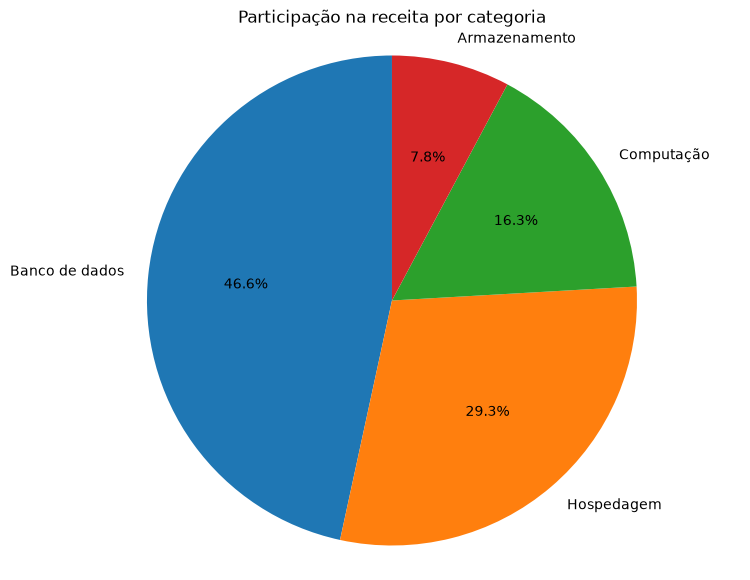

In [16]:
df_pizza = df_receita_por_categoria.copy()

# Criar o gráfico
fig, ax = plt.subplots(figsize=(9, 7))

ax.pie(
    df_pizza["percentual"],
    labels=df_pizza["categoria"],
    autopct="%1.1f%%",
    startangle=90
)

ax.set_title("Participação na receita por categoria")
ax.axis("equal")

plt.show()

In [17]:


df_linha = df_receita_mensal.copy()

df_linha["receita"] = df_linha["valor_total"]

df_linha["data"] = pd.to_datetime({
    "year": df_linha["ano"],
    "month": df_linha["mes"],
    "day": 1
})

# Ordenar cronologicamente
df_linha = df_linha.sort_values("data")

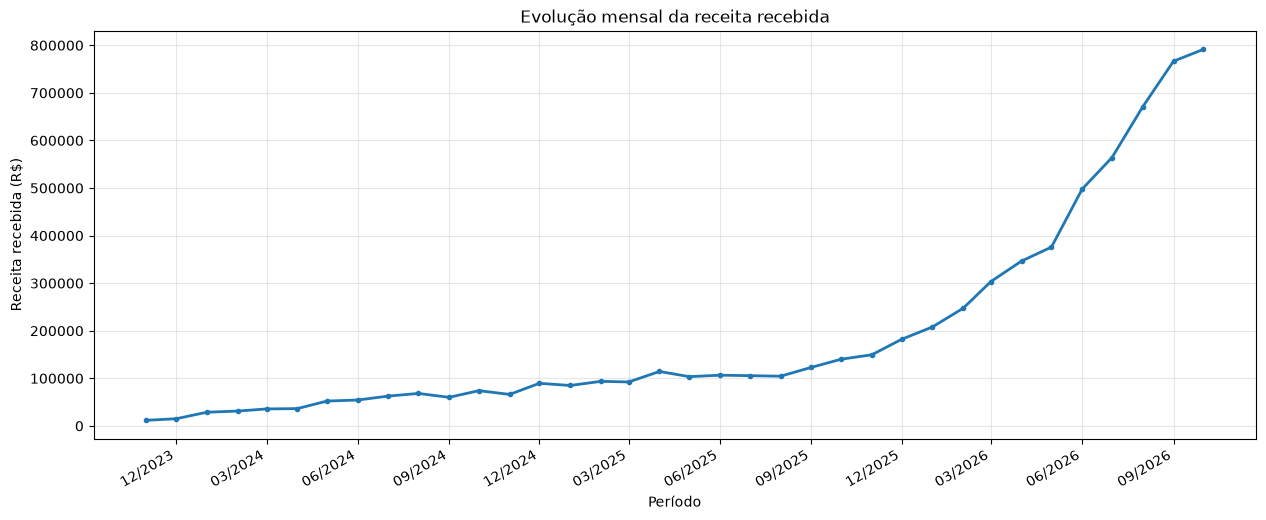

In [18]:
fig, ax = plt.subplots(figsize=(15, 6))

ax.plot(
    df_linha["data"],
    df_linha["receita"],
    marker="o",
    markersize=3,
    linewidth=2
)

# Mostrar datas de três em três meses
ax.xaxis.set_major_locator(
    mdates.MonthLocator(interval=3)
)
ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%m/%Y")
)

ax.set(
    title="Evolução mensal da receita recebida",
    xlabel="Período",
    ylabel="Receita recebida (R$)"
)

ax.grid(alpha=0.3)
fig.autofmt_xdate()
plt.show()

In [19]:
query = """
    SELECT EXTRACT(YEAR FROM p.data_pagamento) AS ano, 
    EXTRACT(MONTH FROM p.data_pagamento) AS mes,
    s.categoria AS categoria,
    SUM(p.valor) AS valor_total
    FROM nexus.pagamentos p
    JOIN nexus.contratos c ON c.id = p.id_contrato
    JOIN nexus.servico s ON c.id_servico = s.id
    WHERE p.data_pagamento IS NOT NULL AND p.status = 'pago'
    GROUP BY ano, mes, categoria
    ORDER BY ano, mes;
"""

df = pd.read_sql(query, engine)
display(df)

df["data"] = pd.to_datetime(
    {
        "year": df["ano"].astype(int),
        "month": df["mes"].astype(int),
        "day": 1
    }
)

df_grafico = df.pivot(
    index="data",
    columns="categoria",
    values="valor_total"
)

display(df_grafico)

,ano,mes,categoria,valor_total
0,2023.0,11.0,Armazenamento,1072.57
1,2023.0,11.0,Banco de dados,4815.02
2,2023.0,11.0,Computação,3380.39
3,2023.0,11.0,Hospedagem,2500.64
4,2023.0,12.0,Armazenamento,2330.81
...,...,...,...,...
139,2026.0,9.0,Hospedagem,234990.31
140,2026.0,10.0,Armazenamento,63940.61
141,2026.0,10.0,Banco de dados,365290.71
142,2026.0,10.0,Computação,116779.89


categoria,Armazenamento,Banco de dados,Computação,Hospedagem
data,,,,
2023-11-01,1072.57,4815.02,3380.39,2500.64
2023-12-01,2330.81,4864.99,2402.72,5513.89
2024-01-01,2757.92,14302.78,6514.62,5227.54
2024-02-01,1800.59,17970.57,5627.29,5817.47
2024-03-01,3107.55,18351.28,6137.02,8088.04
2024-04-01,3816.55,14177.78,7325.46,11076.95
2024-05-01,4924.26,22262.41,11881.18,13184.78
2024-06-01,3790.56,23073.89,14130.49,13417.50
2024-07-01,3620.47,29335.28,13737.48,15829.35


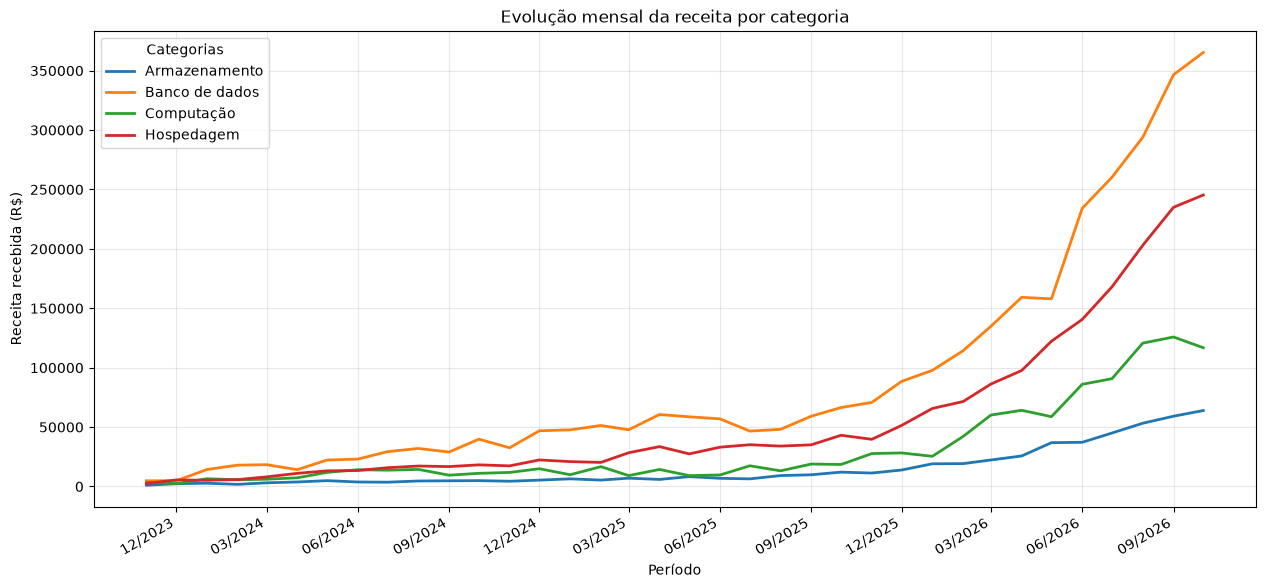

In [20]:
fig, ax = plt.subplots(figsize=(15, 7))

for categoria in df_grafico.columns:
    ax.plot(
        df_grafico.index,
        df_grafico[categoria],
        label=categoria,
        linewidth=2
    )

ax.xaxis.set_major_locator(
    mdates.MonthLocator(interval=3)
)

ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%m/%Y")
)

ax.set(
    title="Evolução mensal da receita por categoria",
    xlabel="Período",
    ylabel="Receita recebida (R$)"
)

ax.legend(title="Categorias")
ax.grid(alpha=0.3)

fig.autofmt_xdate()
plt.show()

In [23]:
query_investigação = """
SELECT
    DATE_TRUNC('month', p.data_pagamento)::date AS mes,
    s.categoria,
    SUM(p.valor) AS receita_recebida,
    COUNT(DISTINCT c.id) AS contratos_pagantes,
    COUNT(DISTINCT p.id) AS pagamentos_recebidos,
    ROUND(
        SUM(p.valor) /
        NULLIF(COUNT(DISTINCT c.id), 0),
        2
    ) AS receita_por_contrato_pagante
FROM nexus.pagamentos p
JOIN nexus.contratos c
    ON c.id = p.id_contrato
JOIN nexus.servico s
    ON s.id = c.id_servico
WHERE p.status = 'pago'
    AND p.data_pagamento IS NOT NULL
GROUP BY mes, s.categoria
ORDER BY mes, s.categoria;
"""
display(pd.read_sql(query_investigação, engine))

,mes,categoria,receita_recebida,contratos_pagantes,pagamentos_recebidos,receita_por_contrato_pagante
0,2023-11-01,Armazenamento,1072.57,9,9,119.17
1,2023-11-01,Banco de dados,4815.02,9,9,535.00
2,2023-11-01,Computação,3380.39,4,4,845.10
3,2023-11-01,Hospedagem,2500.64,12,12,208.39
4,2023-12-01,Armazenamento,2330.81,18,20,129.49
...,...,...,...,...,...,...
139,2026-09-01,Hospedagem,234990.31,912,1071,257.66
140,2026-10-01,Armazenamento,63940.61,635,717,100.69
141,2026-10-01,Banco de dados,365290.71,611,697,597.86
142,2026-10-01,Computação,116779.89,265,294,440.68
